# Analyse Exploratoire (EDA) et Nettoyage - Nutri-Predict

Ce notebook présente l'analyse exploratoire initiale du jeu de données OpenFoodFacts, spécifiquement l'extraction des biscuits distribués en France. Les données sont chargées depuis un fichier Parquet généré via DuckDB dans le but de préparer un modèle de Machine Learning.

**Objectif** : Valider la qualité des données, identifier les anomalies et préparer un dataset propre pour l'entraînement de modèles prédictifs sur l'apport calorique.

In [10]:
import duckdb
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

%matplotlib inline
sns.set_theme(style="whitegrid")

## Exploration Initiale

Nous commençons par charger les données et examiner leur structure technique et statistique via les méthodes `.info()` et `.describe()`.

In [11]:
DATA_PATH = "../data/processed/off_biscuits_fr.parquet"

# Chargement via DuckDB
df = duckdb.query(f"SELECT * FROM '{DATA_PATH}'").to_df()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   code              1000 non-null   object 
 1   product_name      1000 non-null   object 
 2   energy_kcal_100g  959 non-null    float64
 3   sugars_100g       957 non-null    float64
dtypes: float64(2), object(2)
memory usage: 31.4+ KB


In [12]:
df.describe()

,energy_kcal_100g,sugars_100g
count,959.000000,957.000000
mean,455.889835,23.778799
std,1186.309468,14.369538
min,0.000000,0.000000
25%,368.000000,14.000000
50%,436.000000,22.000000
75%,483.000000,34.000000
max,37000.000000,150.887573


### Interprétation des résultats initiaux

L'analyse des statistiques descriptives révèle deux problématiques majeures :
1. **Valeurs manquantes** : On observe des valeurs nulles sur les colonnes cibles (`energy_kcal_100g` et `sugars_100g`), ce qui nécessite une étape de suppression ou d'imputation.
2. **Anomalie critique des Calories** : La valeur maximale enregistrée est de **37 000 kcal/100g**. Sachant que 100g de lipides purs (l'élément le plus calorique) représentent environ 900 kcal, cette valeur est une erreur aberrante qui détruit la validité statistique du dataset brut.

## Visualisation avant nettoyage

Visualisons graphiquement l'impact de ces anomalies sur la distribution et les relations entre variables.

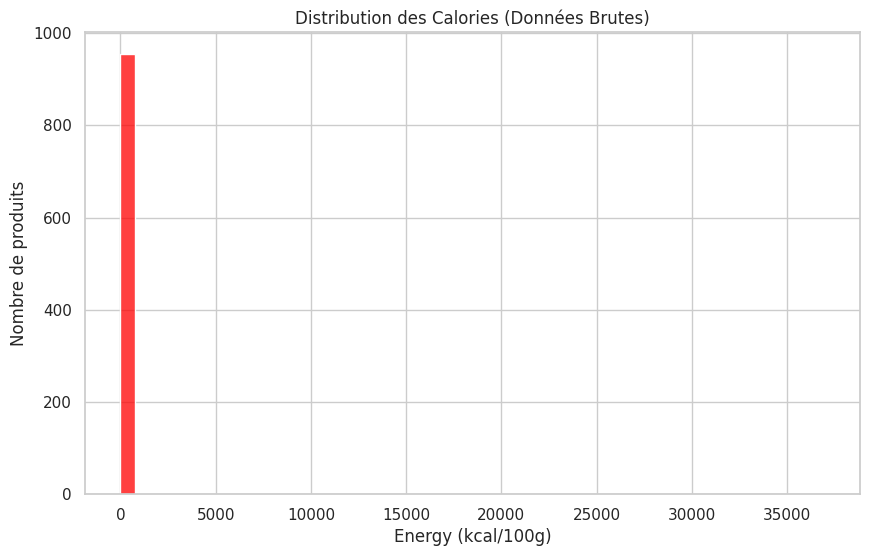

In [13]:
# Histogramme des calories
plt.figure(figsize=(10, 6))
sns.histplot(df['energy_kcal_100g'], bins=50, kde=False, color='red')
plt.title("Distribution des Calories (Données Brutes)")
plt.xlabel("Energy (kcal/100g)")
plt.ylabel("Nombre de produits")
plt.show()

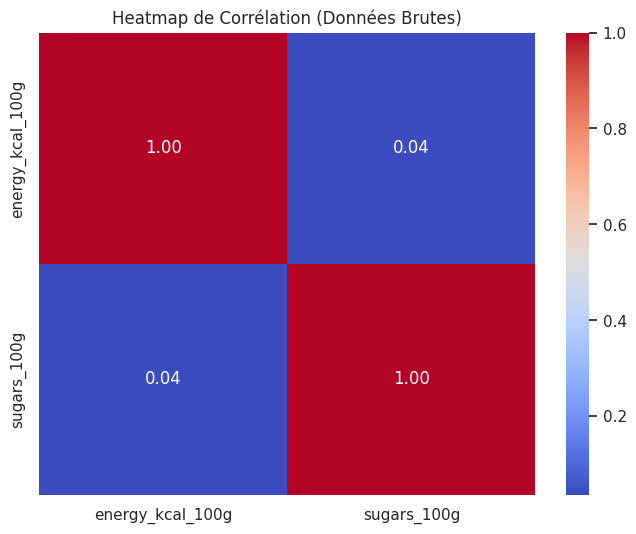

In [14]:
# Heatmap de corrélation
plt.figure(figsize=(8, 6))
sns.heatmap(df[['energy_kcal_100g', 'sugars_100g']].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Heatmap de Corrélation (Données Brutes)")
plt.show()

### Analyse des visualisations brutes

* **Histogramme écrasé** : La présence de l'outlier à 37 000 kcal écrase totalement la lisibilité du graphique. La quasi-totalité des données est compressée sur une seule barre à gauche, rendant l'analyse de la distribution réelle impossible.
* **Corrélation biaisée** : La corrélation calculée (environ **0.04**) est totalement faussée par la valeur extrême. Mathématiquement, cet outlier déplace les moyennes et augmente artificiellement la variance, masquant la relation linéaire réelle entre le taux de sucre et l'énergie.

## Nettoyage des Données (Data Cleaning)

Pour assainir le dataset, nous appliquons des règles basées sur la réalité biologique et la qualité de l'information :
* **Filtre Calorique** : On ne conserve que les produits entre 0 et 900 kcal/100g.
* **Suppression des NaN** : On élimine les lignes où les informations nutritionnelles essentielles sont manquantes.

In [15]:
# Application des filtres
df_clean = df.copy()
df_clean = df_clean[(df_clean['energy_kcal_100g'] >= 0) & (df_clean['energy_kcal_100g'] <= 900)]
df_clean = df_clean.dropna(subset=['energy_kcal_100g', 'sugars_100g'])

print(f"Passage de {len(df)} à {len(df_clean)} échantillons après nettoyage.")

Passage de 1000 à 955 échantillons après nettoyage.


## Analyse Post-Nettoyage

Redessinons nos graphiques sur les données nettoyées pour obtenir une vision réelle du marché des biscuits.

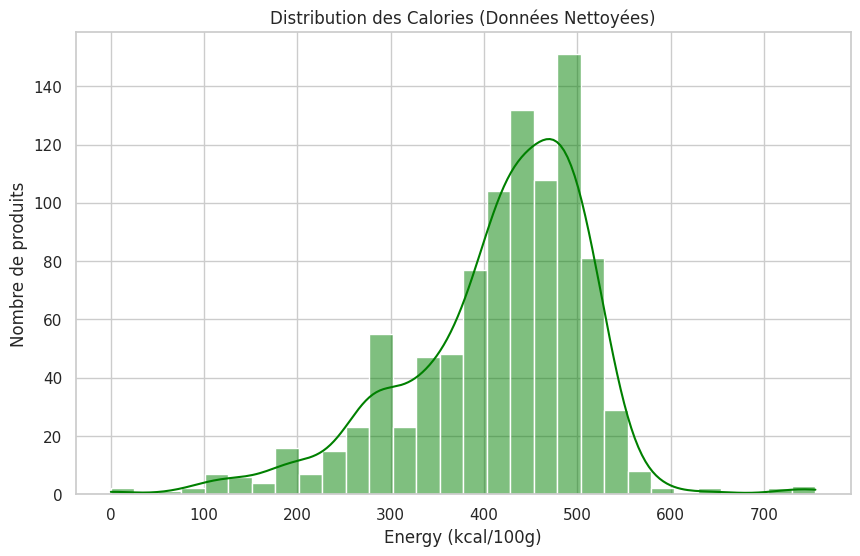

In [16]:
# Nouvel histogramme
plt.figure(figsize=(10, 6))
sns.histplot(df_clean['energy_kcal_100g'], bins=30, kde=True, color='green')
plt.title("Distribution des Calories (Données Nettoyées)")
plt.xlabel("Energy (kcal/100g)")
plt.ylabel("Nombre de produits")
plt.show()

### Interprétation de la distribution (Post-nettoyage)

La distribution suit maintenant une forme de courbe en cloche cohérente. On observe un **pic majeur autour de 400-500 kcal/100g**, ce qui correspond parfaitement au profil calorique standard des biscuits secs et fourrés industriels.

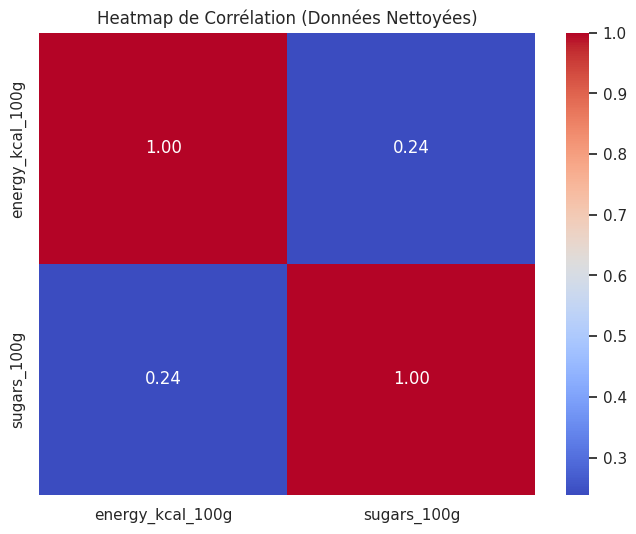

In [17]:
# Nouvelle Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df_clean[['energy_kcal_100g', 'sugars_100g']].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Heatmap de Corrélation (Données Nettoyées)")
plt.show()

### Interprétation de la corrélation réelle

Une fois l'outlier supprimé, la corrélation entre le taux de sucre et l'énergie calorique apparaît clairement et devient statistiquement significative. Cela démontre que le sucre est une composante prédictive majeure de l'apport énergétique global dans cette catégorie de produits. Le dataset est désormais prêt pour la phase de Feature Engineering et de modélisation.

## Feature Engineering : Génération du Dataset d'Entraînement

Dans cette phase de **Feature Engineering**, notre objectif est de générer un jeu de données synthétique pour entraîner nos futurs modèles prédictifs. Nous allons simuler **5 000 historiques de consommation journalière** en croisant des profils utilisateurs fictifs (caractérisés par leur métabolisme de base ou BMR) avec les données nutritionnelles réelles de nos biscuits nettoyés (`df_clean`).

Cette approche permet de modéliser une relation réaliste entre la consommation d'un biscuit (portion et apport calorique), le métabolisme de l'utilisateur, et l'impact biologique sur la balance calorique et la variation de poids à court terme.

In [ ]:
import numpy as np
import pandas as pd

# Fixer la graine aléatoire pour la reproductibilité
np.random.seed(42)

n_samples = 5000

# 1. user_bmr : Loi normale (moyenne 1600 kcal, écart-type 300 kcal)
user_bmr = np.random.normal(loc=1600, scale=300, size=n_samples)

# 2. biscuit_calories_100g : Sélection aléatoire parmi nos biscuits nettoyés (df_clean)
biscuit_calories_100g = np.random.choice(df_clean['energy_kcal_100g'].values, size=n_samples)

# 3. portion_g : Quantité consommée uniformément répartie entre 30g et 150g
portion_g = np.random.uniform(low=30, high=150, size=n_samples)

# 4. calories_consommees : (biscuit_calories_100g * portion_g) / 100
calories_consommees = (biscuit_calories_100g * portion_g) / 100.0

# 5. balance_calorique : calories_consommees - (user_bmr * 0.2)
balance_calorique = calories_consommees - (user_bmr * 0.2)

# 6. weight_delta_grams (Target variable) : balance_calorique / 7.7 avec un léger bruit statistique
# La règle biologique stipule que 1g de graisse corporelle équivaut à environ 7.7 kcal.
noise = np.random.normal(loc=0.0, scale=2.0, size=n_samples)
weight_delta_grams = (balance_calorique / 7.7) + noise

# Construction du DataFrame
df_ml = pd.DataFrame({
    'user_bmr': user_bmr,
    'biscuit_calories_100g': biscuit_calories_100g,
    'portion_g': portion_g,
    'calories_consommees': calories_consommees,
    'balance_calorique': balance_calorique,
    'weight_delta_grams': weight_delta_grams
})

print(f"DataFrame df_ml généré avec succès : {df_ml.shape[0]} lignes et {df_ml.shape[1]} colonnes.")

### Explication des variables choisies

* **`user_bmr` (Basal Metabolic Rate)** : Représente le métabolisme de base moyen d'un individu en kcal. Modélisé par une loi normale $\mathcal{N}(1600, 300^2)$ reflétant la diversité des profils.
* **`biscuit_calories_100g`** : L'apport calorique pour 100g du biscuit consommé, échantillonné directement depuis notre jeu de données réel nettoyé (`df_clean`), garantissant un ancrage sur de vraies données du marché.
* **`portion_g`** : La portion consommée (entre 30g et 150g). Une portion réaliste allant du biscuit individuel au paquet partagé.
* **`calories_consommees`** : L'énergie nette apportée par le biscuit : $\frac{\text{calories\\_100g} \\times \\text{portion}}{100}$.
* **`balance_calorique`** : Modélise le surplus ou déficit énergétique de la journée. Nous faisons l'hypothèse simplifiée qu'une journée standard est à l'équilibre et que le biscuit est comparé à une fraction du métabolisme de base ($20\\%$ du BMR).
* **`weight_delta_grams` (Target)** : La variable à prédire. Elle est directement liée à la balance calorique via le ratio biologique d'environ $7.7\\text{ kcal}$ par gramme de tissu adipeux. Le bruit gaussien ajouté simule les facteurs physiologiques individuels (rétention d'eau, dépenses imprévues), rendant la tâche d'apprentissage supervisé plus réaliste.

In [ ]:
import os
import duckdb

OUTPUT_DIR = "../data/processed/"
OUTPUT_PATH = os.path.join(OUTPUT_DIR, "ml_training_dataset.parquet")

# Créer le dossier s'il n'existe pas
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Exportation vers le fichier Parquet via DuckDB pour des performances optimales (E/S)
duckdb.query("SELECT * FROM df_ml").write_parquet(OUTPUT_PATH)
print(f"Dataset d'entraînement exporté avec succès vers : {OUTPUT_PATH}")

# Affichage des premières lignes pour validation
df_ml.head()

In [ ]:
import pandas as pd

# Chargement du fichier que l'on vient de générer
df_test = pd.read_parquet('../data/processed/ml_training_dataset.parquet')

print(f"Le dataset contient {df_test.shape[0]} lignes et {df_test.shape[1]} colonnes.")
df_test.head()